In [55]:
import sys
sys.path.append('..')

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

from spectraderma_processor import SpectraDermaProcessor

mpl.rcParams['font.family'] = 'arial'
mpl.rcParams['font.size'] = 10

colors = [
    '#8686D2',
    '#7BAED3',
    '#9CCBA0',
    '#E6DC84',
    '#D47291',
    '#868686',
]

def set_ax_size(w,h, ax=None):
    """ w, h: width, height in inches """
    if not ax: ax=plt.gca()
    l = ax.figure.subplotpars.left
    r = ax.figure.subplotpars.right
    t = ax.figure.subplotpars.top
    b = ax.figure.subplotpars.bottom
    figw = float(w)/(r-l)
    figh = float(h)/(t-b)
    ax.figure.set_size_inches(figw, figh)

In [90]:
# Initialize processor
processor = SpectraDermaProcessor(sample_rate=50.0)

# 555S2

In [91]:
processor.load_data('../data/spectraderama_data_2025-04-02_sattac555S2.csv')

# Get raw data for reference
timestamp, channels = processor.get_data()
print(f"Loaded data shape: {channels.shape}")
print(f"First few rows:")
print(pd.DataFrame(channels[:5]))  # Show first few rows like data.head()

Loaded data shape: (456719, 6)
First few rows:
     0    1    2    3    4    5
0  1.0  2.0  5.0  6.0  6.0  4.0
1  1.0  2.0  5.0  6.0  6.0  4.0
2  1.0  2.0  5.0  6.0  6.0  4.0
3  1.0  2.0  5.0  6.0  6.0  4.0
4  1.0  2.0  5.0  6.0  6.0  4.0


c:\Users\y1hli\OneDrive - University of North Carolina at Chapel Hill\github\SpectraDerma\notebooks\..\spectraderma_processor.py:19: DtypeWarning: Columns (3) have mixed types. Specify dtype option on import or set low_memory=False.
  data = pd.read_csv(csv_path)


In [92]:
# Use processor pipeline to get processed data
processor.swt_denoise(wavelet="db2", level=3, zero_levels=(1, 2, 3))
processor.bandpass_filter(low_freq=0.5, high_freq=2.0, order=3)

# Get processed data
timestamp, channels_swt_f = processor.get_data()
print(f"Processed data shape: {channels_swt_f.shape}")

Processed data shape: (456719, 6)


In [94]:
t1 = 2450
t2 = 389100
d = 300

time_limits_1 = (t1, t1 + d)
time_limits_2 = (t2, t2 + d)

amplitude_limits = (-25, 25)

# Use processor's normalize method with both time regions
processor.normalize(time_limits_1, time_limits_2, amplitude_limits=amplitude_limits)

# Get normalized data
timestamp, channels_swt_f_normalized = processor.get_data()
print(f"Normalized data shape: {channels_swt_f_normalized.shape}")

Normalized data shape: (456719, 6)


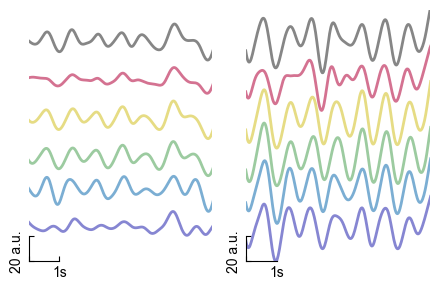

In [96]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(4.5, 3))

sample_rate = processor.sample_rate
y_offset = 30  # Small offset between channels

# Left subplot - first time region
ax_left = axes[0]
for i in range(channels_swt_f_normalized.shape[1]):
    y = channels_swt_f_normalized[:, i] + i * y_offset
    ax_left.plot(timestamp, y, color=colors[i], alpha=1, linewidth=2)

ax_left.set_xlim(*time_limits_1)
ax_left.set_ylim(amplitude_limits[0], amplitude_limits[1] + 5 * y_offset)

# Set spine bounds to show only scale bar segments
# Bottom spine: show only 1 second (30 samples)
ax_left.spines['bottom'].set_bounds(time_limits_1[0], time_limits_1[0] + sample_rate)
# Left spine: show only 20 units
ax_left.spines['left'].set_bounds(amplitude_limits[0], amplitude_limits[0] + 20)

# Hide top and right spines
ax_left.spines['top'].set_visible(False)
ax_left.spines['right'].set_visible(False)

# Set custom ticks for the scale bars
ax_left.set_xticks([time_limits_1[0], time_limits_1[0] + sample_rate])
ax_left.set_xticklabels(['', '1s'])
ax_left.set_yticks([amplitude_limits[0], amplitude_limits[0] + 20])
ax_left.set_yticklabels(['', '20 a.u.'], rotation=90)

ax_left.tick_params(axis='both', which='both', direction='in')

# Right subplot - second time region
ax_right = axes[1]
for i in range(channels_swt_f_normalized.shape[1]):
    y = channels_swt_f_normalized[:, i] + i * y_offset
    ax_right.plot(timestamp, y, color=colors[i], alpha=1, linewidth=2)

ax_right.set_xlim(*time_limits_2)
ax_right.set_ylim(amplitude_limits[0], amplitude_limits[1] + 5 * y_offset)

# Set spine bounds to show only scale bar segments
# Bottom spine: show only 1 second (30 samples)
ax_right.spines['bottom'].set_bounds(time_limits_2[0], time_limits_2[0] + sample_rate)
# Left spine: show only 20 units
ax_right.spines['left'].set_bounds(amplitude_limits[0], amplitude_limits[0] + 20)

# Hide top and right spines
ax_right.spines['top'].set_visible(False)
ax_right.spines['right'].set_visible(False)

# Set custom ticks for the scale bars
ax_right.set_xticks([time_limits_2[0], time_limits_2[0] + sample_rate])
ax_right.set_xticklabels(['', '1s'])
ax_right.set_yticks([amplitude_limits[0], amplitude_limits[0] + 20])
ax_right.set_yticklabels(['', '20 a.u.'], rotation=90)

ax_right.tick_params(axis='both', which='both', direction='in')

plt.tight_layout()
# plt.savefig('../figures/fig1/mode_a_sample.png', dpi=600, bbox_inches='tight')
plt.show()


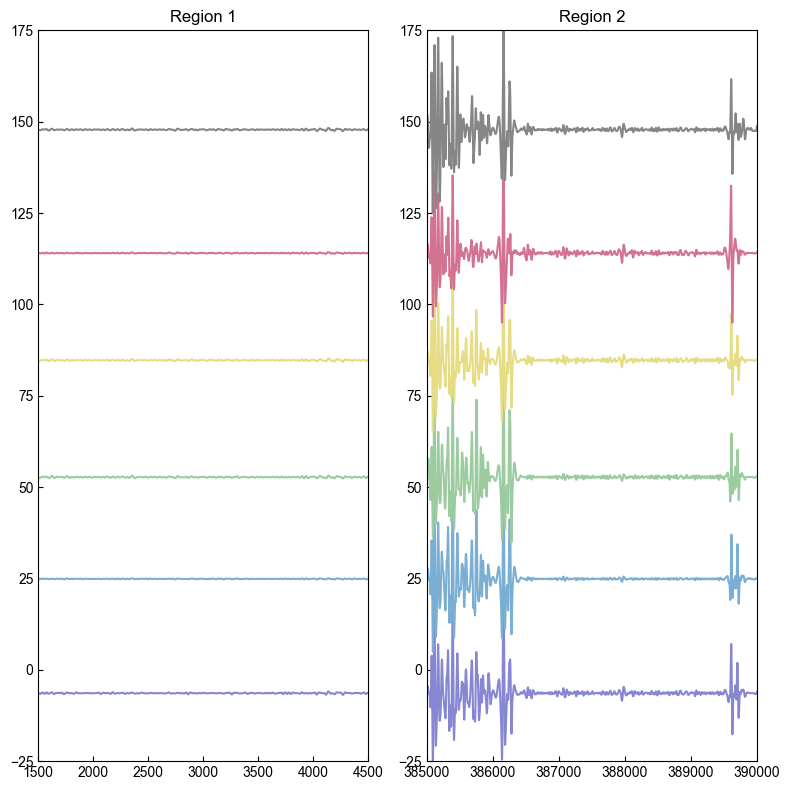

In [107]:
ppg_region_start_1 = 1500
ppg_region_end_1 = 4500

ppg_region_start_2 = 385000
ppg_region_end_2 = 390000

ppg_region_1 = (ppg_region_start_1, ppg_region_end_1)
ppg_region_2 = (ppg_region_start_2, ppg_region_end_2)

amplitude_limits = (-25, 25)

processor.normalize(ppg_region_1, ppg_region_2, amplitude_limits=amplitude_limits)
timestamp, channels_swt_f_normalized = processor.get_data()

y_offset = 30  # Small offset between channels

fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(8, 8))

for ch in range(channels_swt_f_normalized.shape[1]):
    y = channels_swt_f_normalized[:, ch] + ch * y_offset
    ax1.plot(timestamp, y, color=colors[ch], linewidth=1.5)
    ax2.plot(timestamp, y, color=colors[ch], linewidth=1.5)

ax1.set_xlim(*ppg_region_1)
ax2.set_xlim(*ppg_region_2)

ax1.set_ylim(amplitude_limits[0], amplitude_limits[1] + 5 * y_offset)
ax2.set_ylim(amplitude_limits[0], amplitude_limits[1] + 5 * y_offset)

ax1.set_title("Region 1")
ax2.set_title("Region 2")

for ax in (ax1, ax2):
    ax.tick_params(direction='in')

plt.tight_layout()
plt.show()

# 520S2

In [208]:
processor.load_data('../data/spectraderama_data_2025-03-25_sattac520S2.csv')

# Get raw data for reference
timestamp, channels = processor.get_data()
print(f"Loaded data shape: {channels.shape}")
print(f"First few rows:")
print(pd.DataFrame(channels[:5]))  # Show first few rows like data.head()

Loaded data shape: (426807, 6)
First few rows:
      0     1     2      3      4     5
0  29.0  32.0  83.0  277.0  465.0  78.0
1  29.0  32.0  83.0  277.0  465.0  78.0
2  28.0  31.0  80.0  267.0  448.0  76.0
3  28.0  31.0  80.0  267.0  447.0  75.0
4  28.0  31.0  80.0  267.0  449.0  75.0


In [209]:
# Use processor pipeline to get processed data
processor.swt_denoise(wavelet="db2", level=3, zero_levels=(1, 2, 3))
processor.bandpass_filter(low_freq=0.5, high_freq=3.0, order=3)

# Get processed data
timestamp, channels_swt_f = processor.get_data()
print(f"Processed data shape: {channels_swt_f.shape}")

Processed data shape: (426807, 6)


In [210]:
t1 = 250
t2 = 423000
d = 500

time_limits_1 = (t1, t1 + d)
time_limits_2 = (t2, t2 + d)

amplitude_limits = (-25, 25)

# Use processor's normalize method with both time regions
processor.normalize(time_limits_1, time_limits_2, amplitude_limits=amplitude_limits)

# Get normalized data
timestamp, channels_swt_f_normalized = processor.get_data()
print(f"Normalized data shape: {channels_swt_f_normalized.shape}")

Normalized data shape: (426807, 6)


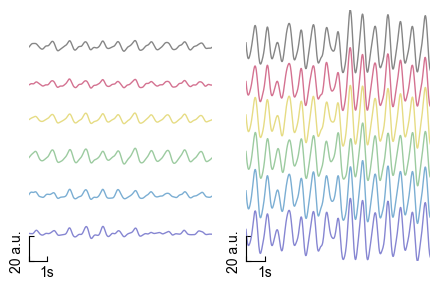

In [212]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(4.5, 3))

sample_rate = processor.sample_rate
y_offset = 30  # Small offset between channels

# Left subplot - first time region
ax_left = axes[0]
for i in range(channels_swt_f_normalized.shape[1]):
    y = channels_swt_f_normalized[:, i] + i * y_offset
    ax_left.plot(timestamp, y, color=colors[i], alpha=1, linewidth=1)

ax_left.set_xlim(*time_limits_1)
ax_left.set_ylim(amplitude_limits[0], amplitude_limits[1] + 5 * y_offset)

# Set spine bounds to show only scale bar segments
# Bottom spine: show only 1 second (50 samples)
ax_left.spines['bottom'].set_bounds(time_limits_1[0], time_limits_1[0] + sample_rate)
# Left spine: show only 20 units
ax_left.spines['left'].set_bounds(amplitude_limits[0], amplitude_limits[0] + 20)

# Hide top and right spines
ax_left.spines['top'].set_visible(False)
ax_left.spines['right'].set_visible(False)

# Set custom ticks for the scale bars
ax_left.set_xticks([time_limits_1[0], time_limits_1[0] + sample_rate])
ax_left.set_xticklabels(['', '1s'])
ax_left.set_yticks([amplitude_limits[0], amplitude_limits[0] + 20])
ax_left.set_yticklabels(['', '20 a.u.'], rotation=90)

ax_left.tick_params(axis='both', which='both', direction='in')

# Right subplot - second time region
ax_right = axes[1]
for i in range(channels_swt_f_normalized.shape[1]):
    y = channels_swt_f_normalized[:, i] + i * y_offset
    ax_right.plot(timestamp, y, color=colors[i], alpha=1, linewidth=1)

ax_right.set_xlim(*time_limits_2)
ax_right.set_ylim(amplitude_limits[0], amplitude_limits[1] + 5 * y_offset)

# Set spine bounds to show only scale bar segments
# Bottom spine: show only 1 second (50 samples)
ax_right.spines['bottom'].set_bounds(time_limits_2[0], time_limits_2[0] + sample_rate)
# Left spine: show only 20 units
ax_right.spines['left'].set_bounds(amplitude_limits[0], amplitude_limits[0] + 20)

# Hide top and right spines
ax_right.spines['top'].set_visible(False)
ax_right.spines['right'].set_visible(False)

# Set custom ticks for the scale bars
ax_right.set_xticks([time_limits_2[0], time_limits_2[0] + sample_rate])
ax_right.set_xticklabels(['', '1s'])
ax_right.set_yticks([amplitude_limits[0], amplitude_limits[0] + 20])
ax_right.set_yticklabels(['', '20 a.u.'], rotation=90)

ax_right.tick_params(axis='both', which='both', direction='in')

plt.tight_layout()
plt.savefig('../figures/fig1/mode_a_sample.png', dpi=600, bbox_inches='tight')
plt.show()


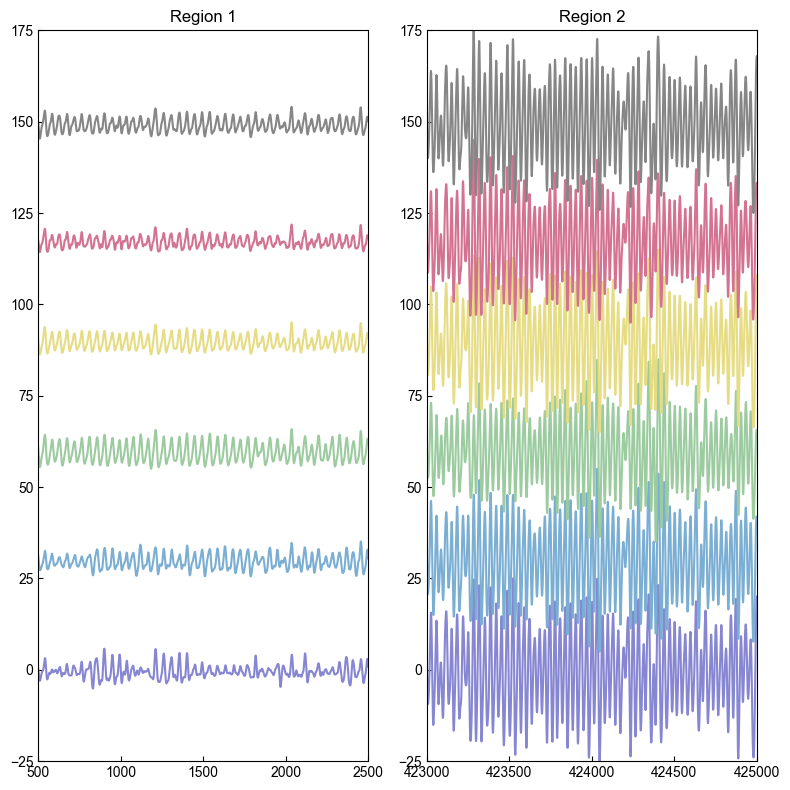

In [213]:
ppg_region_start_1 = 500
ppg_region_end_1 = 2500

ppg_region_start_2 = 423000
ppg_region_end_2 = 425000

ppg_region_1 = (ppg_region_start_1, ppg_region_end_1)
ppg_region_2 = (ppg_region_start_2, ppg_region_end_2)

amplitude_limits = (-25, 25)

processor.normalize(ppg_region_1, ppg_region_2, amplitude_limits=amplitude_limits)
timestamp, channels_swt_f_normalized = processor.get_data()

sample_rate = 30.0
y_offset = 30  # Small offset between channels

fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(8, 8))

for ch in range(channels_swt_f_normalized.shape[1]):
    y = channels_swt_f_normalized[:, ch] + ch * y_offset
    ax1.plot(timestamp, y, color=colors[ch], linewidth=1.5)
    ax2.plot(timestamp, y, color=colors[ch], linewidth=1.5)

ax1.set_xlim(*ppg_region_1)
ax2.set_xlim(*ppg_region_2)

ax1.set_ylim(amplitude_limits[0], amplitude_limits[1] + 5 * y_offset)
ax2.set_ylim(amplitude_limits[0], amplitude_limits[1] + 5 * y_offset)

ax1.set_title("Region 1")
ax2.set_title("Region 2")

for ax in (ax1, ax2):
    ax.tick_params(direction='in')

plt.tight_layout()
plt.show()

## for fig3

### AC

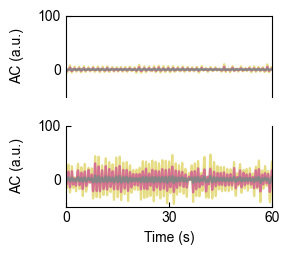

In [221]:
processor = SpectraDermaProcessor(sample_rate=50.0)
processor.load_data('../data/spectraderama_data_2025-03-25_sattac520S2.csv')
processor.swt_denoise(wavelet="db2", level=3, zero_levels=(1, 2, 3)).bandpass_filter(low_freq=0.5, high_freq=3.0, order=3)
timestamp, channels_ac = processor.get_data()


fig, (ax1, ax2) = plt.subplots(nrows=2, ncols=1, figsize=(3, 2.65))

for ch in range(channels_ac.shape[1]):
    y = channels_ac[:, ch]
    ax1.plot(timestamp, y, color=colors[ch], linewidth=1.5)
    ax2.plot(timestamp, y, color=colors[ch], linewidth=1.5)

ax1.set_xlim(*ppg_region_1)
ax2.set_xlim(*ppg_region_2)

# ax1.set_ylim(amplitude_limits[0], amplitude_limits[1])
# ax2.set_ylim(amplitude_limits[0], amplitude_limits[1])

# Ensure exactly three ticks on both axes for each subplot
for ax in (ax1, ax2):
    ax.tick_params(direction='in')
    ax.tick_params(axis='y')
    ax.set_ylabel('AC (a.u.)', labelpad=10)

x1, x2 = ax.get_xlim()
ax2.set_xticks([x1, (x1 + x2) / 2, x2])
ax2.set_xticklabels([0, 30, 60])
ax2.set_xlabel('Time (s)')

ax1.set_ylim(-50, 100)
ax2.set_ylim(-50, 100)

ax1.spines['bottom'].set_visible(False)
ax2.spines['top'].set_visible(False)
ax1.set_xticks([])

plt.tight_layout()
# plt.savefig('../figures/fig3/mode_a_ac.png', dpi=600, bbox_inches='tight', transparent=True)
plt.show()

#### AC stats

In [222]:
from scipy.signal import find_peaks, peak_widths
import matplotlib.patches as patches

def analyze_pulses_comprehensive(data, region_start, region_end, reference_channel=2, sample_rate=30.0, tolerance_samples=15):
    """
    Comprehensive pulse analysis using reference channel with cross-channel validation
    
    Parameters:
    - data: processed channel data (N_samples x N_channels)
    - region_start, region_end: indices for the region to analyze
    - reference_channel: channel index to use as reference (default: 2 for green)
    - sample_rate: sampling rate in Hz (not hardcoded)
    - tolerance_samples: tolerance for matching peaks across channels
    
    Returns:
    - pulse_data: (N_peaks, 3, N_channels) array [height, interval, width]
    - peak_locations: (N_peaks, N_channels) array of peak indices
    - timestamps: timestamp array for the region
    """
    
    region_data = data[region_start:region_end, :]
    region_timestamps = np.arange(region_start, region_end)
    n_channels = region_data.shape[1]
    
    print(f"\n=== Comprehensive Pulse Analysis ===")
    print(f"Region: {region_start} to {region_end} (samples)")
    print(f"Duration: {(region_end - region_start) / sample_rate:.1f} seconds")
    print(f"Sample rate: {sample_rate} Hz")
    print(f"Reference channel: {reference_channel} (Green)")
    print(f"Tolerance: {tolerance_samples} samples ({tolerance_samples/sample_rate:.2f}s)")
    
    # Step 1: Find peaks in reference channel
    ref_signal = region_data[:, reference_channel]
    ref_peaks, _ = find_peaks(ref_signal, 
                             height=np.percentile(ref_signal, 70),  # Adaptive threshold
                             distance=int(sample_rate * 0.4))  # Min 0.4s between peaks
    
    print(f"Initial peaks found in reference channel: {len(ref_peaks)}")
    
    # Step 2: Find corresponding peaks in all channels
    all_channel_peaks = []
    valid_peak_mask = []
    
    for ref_peak in ref_peaks:
        peak_group = []
        valid_peak = True
        
        for ch in range(n_channels):
            ch_signal = region_data[:, ch]
            
            # Search for peak in tolerance window around reference peak
            search_start = max(0, ref_peak - tolerance_samples)
            search_end = min(len(ch_signal), ref_peak + tolerance_samples + 1)
            search_region = ch_signal[search_start:search_end]
            
            if len(search_region) == 0:
                valid_peak = False
                break
                
            # Find local peaks in search region
            local_peaks, _ = find_peaks(search_region, height=np.percentile(ch_signal, 60))
            
            if len(local_peaks) == 0:
                valid_peak = False
                break
            
            # Choose the peak closest to reference position
            global_peaks = local_peaks + search_start
            distances = np.abs(global_peaks - ref_peak)
            closest_peak_idx = np.argmin(distances)
            closest_peak = global_peaks[closest_peak_idx]
            
            # Check if closest peak is within tolerance
            if distances[closest_peak_idx] > tolerance_samples:
                valid_peak = False
                break
                
            peak_group.append(closest_peak)
        
        if valid_peak:
            all_channel_peaks.append(peak_group)
            valid_peak_mask.append(True)
        else:
            valid_peak_mask.append(False)
    
    valid_peaks = np.array(all_channel_peaks)  # Shape: (N_valid_peaks, N_channels)
    
    print(f"Valid peaks after cross-channel validation: {len(valid_peaks)}")
    if len(valid_peaks) == 0:
        print("No valid peaks found!")
        return None, None, region_timestamps
    
    # Step 3: Calculate pulse characteristics
    n_valid_peaks = len(valid_peaks)
    pulse_data = np.zeros((n_valid_peaks, 3, n_channels))  # [height, interval, width]
    
    for ch in range(n_channels):
        ch_signal = region_data[:, ch]
        ch_peaks = valid_peaks[:, ch]
        
        # Heights
        pulse_data[:, 0, ch] = ch_signal[ch_peaks]
        
        # Intervals (time between consecutive peaks)
        if n_valid_peaks > 1:
            intervals_samples = np.diff(ch_peaks)
            intervals_seconds = intervals_samples / sample_rate
            pulse_data[1:, 1, ch] = intervals_seconds  # First peak has no previous interval
            pulse_data[0, 1, ch] = np.nan  # Mark first interval as NaN
        
        # Widths (full width at half maximum)
        try:
            widths, _, _, _ = peak_widths(ch_signal, ch_peaks, rel_height=0.5)
            pulse_data[:, 2, ch] = widths / sample_rate  # Convert to seconds
        except:
            pulse_data[:, 2, ch] = np.nan
    
    return pulse_data, valid_peaks, region_timestamps

def print_pulse_statistics(pulse_data, sample_rate=30.0):
    """Print comprehensive statistics for pulse analysis"""
    if pulse_data is None:
        print("No pulse data to analyze")
        return
        
    n_peaks, _, n_channels = pulse_data.shape
    channel_names = ['Ch0', 'Ch1', 'Ch2(Green)', 'Ch3', 'Ch4', 'Ch5']
    
    print(f"\n=== Pulse Statistics ===")
    print(f"Number of valid peaks: {n_peaks}")
    print(f"Number of channels: {n_channels}")
    
    for ch in range(n_channels):
        print(f"\n{channel_names[ch]}:")
        
        # Heights
        heights = pulse_data[:, 0, ch]
        print(f"  Peak Heights: {np.mean(heights):.2f} ± {np.std(heights):.2f} a.u.")
        
        # Intervals (excluding NaN first value)
        intervals = pulse_data[1:, 1, ch]  # Skip first NaN interval
        if len(intervals) > 0 and not np.all(np.isnan(intervals)):
            valid_intervals = intervals[~np.isnan(intervals)]
            if len(valid_intervals) > 0:
                mean_interval = np.mean(valid_intervals)
                std_interval = np.std(valid_intervals)
                pulse_rate = 60.0 / mean_interval if mean_interval > 0 else 0
                print(f"  Pulse Intervals: {mean_interval:.3f} ± {std_interval:.3f} s")
                print(f"  Pulse Rate: {pulse_rate:.1f} BPM")
            else:
                print(f"  Pulse Intervals: No valid intervals")
        else:
            print(f"  Pulse Intervals: Insufficient data")
        
        # Widths
        widths = pulse_data[:, 2, ch]
        if not np.all(np.isnan(widths)):
            valid_widths = widths[~np.isnan(widths)]
            if len(valid_widths) > 0:
                print(f"  Pulse Widths (FWHM): {np.mean(valid_widths):.3f} ± {np.std(valid_widths):.3f} s")
            else:
                print(f"  Pulse Widths: No valid widths")
        else:
            print(f"  Pulse Widths: Could not calculate")

def visualize_peaks_section(data, peaks, region_start, region_end, 
                          sample_rate=30.0, vis_duration=5.0, vis_start_offset=0):
    """
    Visualize a section of data with marked peaks
    
    Parameters:
    - data: channel data
    - peaks: peak locations array (N_peaks, N_channels)
    - region_start, region_end: original region bounds
    - sample_rate: sampling rate in Hz
    - vis_duration: duration to visualize in seconds
    - vis_start_offset: offset from region start in seconds
    """
    if peaks is None or len(peaks) == 0:
        print("No peaks to visualize")
        return
        
    # Calculate visualization window
    vis_samples = int(vis_duration * sample_rate)
    vis_start_sample = region_start + int(vis_start_offset * sample_rate)
    vis_end_sample = vis_start_sample + vis_samples
    
    # Ensure we don't go beyond data bounds
    vis_start_sample = max(vis_start_sample, 0)
    vis_end_sample = min(vis_end_sample, data.shape[0])
    
    vis_data = data[vis_start_sample:vis_end_sample, :]
    vis_timestamps = np.arange(vis_start_sample, vis_end_sample) / sample_rate
    
    # Find peaks within visualization window
    vis_peaks = []
    for peak_group in peaks:
        vis_peak_group = []
        for ch_peak in peak_group:
            global_peak = region_start + ch_peak
            if vis_start_sample <= global_peak < vis_end_sample:
                vis_peak_group.append(global_peak - vis_start_sample)
            else:
                vis_peak_group.append(None)
        vis_peaks.append(vis_peak_group)
    
    # Create visualization
    fig, axes = plt.subplots(nrows=6, ncols=1, figsize=(6, 6), sharex=True)
    channel_names = ['Ch0', 'Ch1', 'Ch2 (Green-Ref)', 'Ch3', 'Ch4', 'Ch5']
    
    for ch in range(6):
        ax = axes[ch]
        
        # Plot signal
        ax.plot(vis_timestamps, vis_data[:, ch], color=colors[ch], linewidth=1.5, alpha=0.8)
        
        # Mark peaks
        for peak_group in vis_peaks:
            if peak_group[ch] is not None:
                peak_time = vis_timestamps[peak_group[ch]]
                peak_value = vis_data[peak_group[ch], ch]
                ax.plot(peak_time, peak_value, 'ro', markersize=6, markerfacecolor='red', 
                       markeredgecolor='darkred', markeredgewidth=1)
        
        ax.set_ylabel(f'{channel_names[ch]}\n(a.u.)', fontsize=10)
        ax.grid(True, alpha=0.3)
        ax.tick_params(direction='in')
        
        # Highlight reference channel
        if ch == 2:
            ax.set_facecolor('#f0f8ff')
    
    axes[-1].set_xlabel('Time (s)', fontsize=12)
    plt.suptitle(f'Pulse Detection Visualization ({vis_duration}s section)\nRed dots: Detected peaks', 
                fontsize=14, y=0.98)
    plt.tight_layout()
    plt.show()
    
    # Print peak count in visualization window
    total_peaks_in_window = sum(1 for peak_group in vis_peaks if any(p is not None for p in peak_group))
    print(f"Peaks visible in {vis_duration}s window: {total_peaks_in_window}")

# Perform comprehensive pulse analysis for both regions
print("="*80)
print("COMPREHENSIVE PULSE ANALYSIS FOR BOTH REGIONS")
print("="*80)

# Make sure we have AC data
processor.reset()
processor.swt_denoise(wavelet="db2", level=3, zero_levels=(1, 2, 3)).bandpass_filter(low_freq=0.5, high_freq=3, order=3)
timestamp, channels_ac = processor.get_data()


current_sample_rate = 50.0  # Ensure sample rate is defined

# Analyze Region 1
print("\n" + "="*50)
print("REGION 1 ANALYSIS")
print("="*50)
pulse_data_1, peaks_1, timestamps_1 = analyze_pulses_comprehensive(
    channels_ac, ppg_region_start_1, ppg_region_end_1, 
    reference_channel=2, sample_rate=current_sample_rate
)
print_pulse_statistics(pulse_data_1, current_sample_rate)

# Analyze Region 2  
print("\n" + "="*50)
print("REGION 2 ANALYSIS")
print("="*50)
pulse_data_2, peaks_2, timestamps_2 = analyze_pulses_comprehensive(
    channels_ac, ppg_region_start_2, ppg_region_end_2,
    reference_channel=2, sample_rate=current_sample_rate
)
print_pulse_statistics(pulse_data_2, current_sample_rate)

COMPREHENSIVE PULSE ANALYSIS FOR BOTH REGIONS

REGION 1 ANALYSIS

=== Comprehensive Pulse Analysis ===
Region: 500 to 2500 (samples)
Duration: 40.0 seconds
Sample rate: 50.0 Hz
Reference channel: 2 (Green)
Tolerance: 15 samples (0.30s)
Initial peaks found in reference channel: 44
Valid peaks after cross-channel validation: 44

=== Pulse Statistics ===
Number of valid peaks: 44
Number of channels: 6

Ch0:
  Peak Heights: 0.29 ± 0.17 a.u.
  Pulse Intervals: 0.909 ± 0.139 s
  Pulse Rate: 66.0 BPM
  Pulse Widths (FWHM): 0.326 ± 0.112 s

Ch1:
  Peak Heights: 0.45 ± 0.15 a.u.
  Pulse Intervals: 0.909 ± 0.121 s
  Pulse Rate: 66.0 BPM
  Pulse Widths (FWHM): 0.362 ± 0.078 s

Ch2(Green):
  Peak Heights: 2.44 ± 0.54 a.u.
  Pulse Intervals: 0.910 ± 0.118 s
  Pulse Rate: 65.9 BPM
  Pulse Widths (FWHM): 0.361 ± 0.056 s

Ch3:
  Peak Heights: 5.54 ± 1.57 a.u.
  Pulse Intervals: 0.910 ± 0.118 s
  Pulse Rate: 65.9 BPM
  Pulse Widths (FWHM): 0.357 ± 0.052 s

Ch4:
  Peak Heights: 2.43 ± 0.97 a.u.
  Pulse 


PEAK VISUALIZATION

Region 1 Visualization:


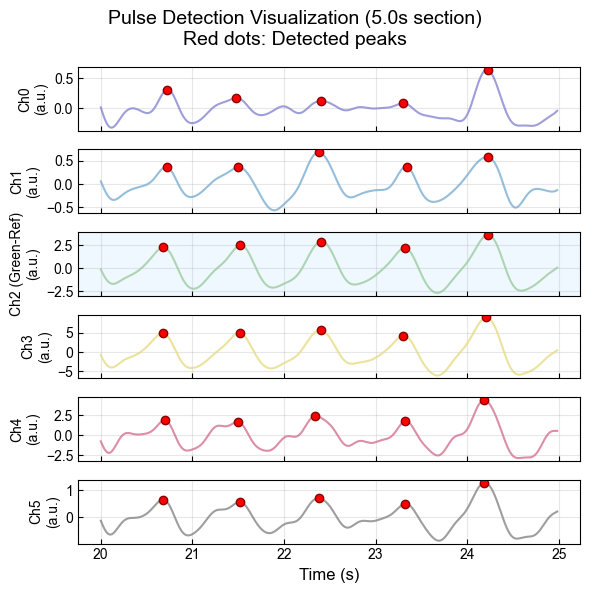

Peaks visible in 5.0s window: 5

Region 2 Visualization:


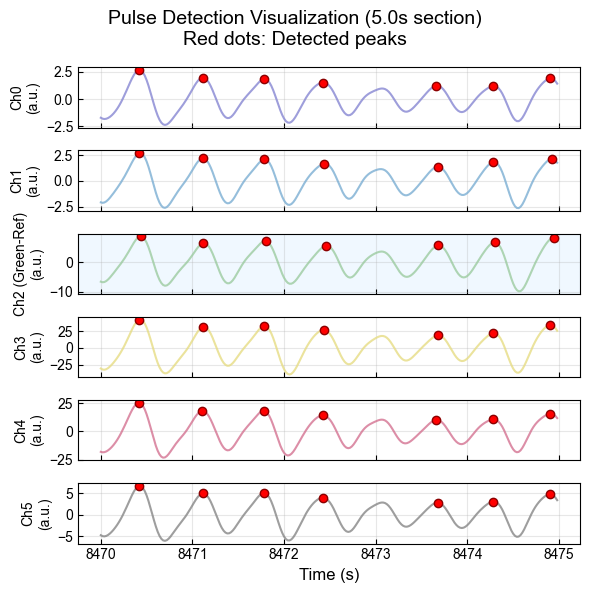

Peaks visible in 5.0s window: 7

PULSE CHARACTERISTICS COMPARISON
Channel      Region   Peaks  Height(a.u.) Rate(BPM)  Width(s)  
----------------------------------------------------------------------
Ch0          Region1  44     0.29         66.0       0.326     
Ch0          Region2  56     1.68         85.1       0.320     

Ch1          Region1  44     0.45         66.0       0.362     
Ch1          Region2  56     2.23         85.1       0.328     

Ch2(Green)   Region1  44     2.44         65.9       0.361     
Ch2(Green)   Region2  56     8.08         85.1       0.318     

Ch3          Region1  44     5.54         65.9       0.357     
Ch3          Region2  56     28.96        85.1       0.329     

Ch4          Region1  44     2.43         66.0       0.370     
Ch4          Region2  56     15.91        85.1       0.319     

Ch5          Region1  44     0.78         66.0       0.368     
Ch5          Region2  56     4.33         85.1       0.320     


Results stored in variab

In [223]:
# Visualize peaks for both regions
print("\n" + "="*60)
print("PEAK VISUALIZATION")
print("="*60)

if peaks_1 is not None and len(peaks_1) > 0:
    print("\nRegion 1 Visualization:")
    visualize_peaks_section(channels_ac, peaks_1, ppg_region_start_1, ppg_region_end_1,
                           current_sample_rate, vis_duration=5.0, vis_start_offset=10)

if peaks_2 is not None and len(peaks_2) > 0:
    print("\nRegion 2 Visualization:")
    visualize_peaks_section(channels_ac, peaks_2, ppg_region_start_2, ppg_region_end_2,
                           current_sample_rate, vis_duration=5.0, vis_start_offset=10)

# Create summary comparison table
if pulse_data_1 is not None and pulse_data_2 is not None:
    print("\n" + "="*80)
    print("PULSE CHARACTERISTICS COMPARISON")
    print("="*80)
    
    channel_names = ['Ch0', 'Ch1', 'Ch2(Green)', 'Ch3', 'Ch4', 'Ch5']
    
    print(f"{'Channel':<12} {'Region':<8} {'Peaks':<6} {'Height(a.u.)':<12} {'Rate(BPM)':<10} {'Width(s)':<10}")
    print("-" * 70)
    
    for ch in range(6):
        for region_idx, (pulse_data, region_name) in enumerate([(pulse_data_1, "Region1"), (pulse_data_2, "Region2")]):
            n_peaks = pulse_data.shape[0]
            
            # Heights
            heights = pulse_data[:, 0, ch]
            mean_height = np.mean(heights)
            
            # Pulse rate
            intervals = pulse_data[1:, 1, ch]
            valid_intervals = intervals[~np.isnan(intervals)]
            if len(valid_intervals) > 0:
                pulse_rate = 60.0 / np.mean(valid_intervals)
            else:
                pulse_rate = 0
            
            # Widths
            widths = pulse_data[:, 2, ch]
            valid_widths = widths[~np.isnan(widths)]
            if len(valid_widths) > 0:
                mean_width = np.mean(valid_widths)
            else:
                mean_width = 0
            
            print(f"{channel_names[ch]:<12} {region_name:<8} {n_peaks:<6} {mean_height:<12.2f} {pulse_rate:<10.1f} {mean_width:<10.3f}")
        print()  # Empty line between channels

# Store results for later use
print(f"\nResults stored in variables:")
print(f"- pulse_data_1: {pulse_data_1.shape if pulse_data_1 is not None else 'None'}")
print(f"- pulse_data_2: {pulse_data_2.shape if pulse_data_2 is not None else 'None'}")
print(f"- peaks_1: {peaks_1.shape if peaks_1 is not None else 'None'}")
print(f"- peaks_2: {peaks_2.shape if peaks_2 is not None else 'None'}")

#### t-test


PULSE HEIGHT STATISTICAL SUMMARY
Channel    Region1 Mean±SD    Region2 Mean±SD    p-value    Significance
----------------------------------------------------------------------
Ch0       0.29±0.17        1.68±0.47        0.0000     ***
Ch1       0.45±0.15        2.23±0.56        0.0000     ***
Ch2       2.44±0.54        8.08±2.37        0.0000     ***
Ch3       5.54±1.57        28.96±8.21        0.0000     ***
Ch4       2.43±0.97        15.91±4.95        0.0000     ***
Ch5       0.78±0.24        4.33±1.27        0.0000     ***


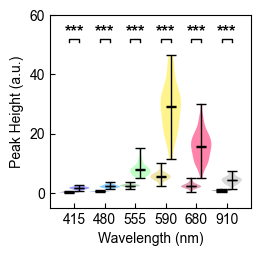

In [265]:
from scipy import stats
import matplotlib.colors as mcolors

def add_significance_bracket(ax, x1, x2, y, p_value, height_offset=0.1):
    """Add significance bracket to plot"""
    # Determine significance level
    if p_value < 0.001:
        sig_text = '***'
    elif p_value < 0.01:
        sig_text = '**'
    elif p_value < 0.05:
        sig_text = '*'
    else:
        sig_text = 'ns'
    
    # Draw bracket
    bracket_height = y + height_offset
    ax.plot([x1, x1, x2, x2], [y, bracket_height, bracket_height, y], 'k-', linewidth=1)
    
    # Add significance text
    ax.text((x1 + x2) / 2, bracket_height + 0.02, sig_text, 
            ha='center', va='bottom', fontsize=12, fontweight='bold')
    
    return bracket_height + 0.05

def make_color_brighter(color, factor=1.5):
    """Make a color brighter by increasing its saturation and lightness"""
    # Convert to HSV for easier manipulation
    rgb = mcolors.to_rgb(color)
    hsv = mcolors.rgb_to_hsv(rgb)
    
    # Increase saturation and lightness
    new_hsv = [hsv[0], min(1.0, hsv[1] * factor), min(1.0, hsv[2] * factor)]
    
    # Convert back to RGB
    new_rgb = mcolors.hsv_to_rgb(new_hsv)
    return new_rgb

# Prepare data for plotting - Heights only
channel_names = ['Ch0', 'Ch1', 'Ch2', 'Ch3', 'Ch4', 'Ch5']

# Create data for plotting
plot_data = []
plot_labels = []
plot_colors = []

# Position mapping for x-axis - Six pairs with spacing
pair_spacing = 3  # Space between pairs
positions = {}

for ch in range(6):
    # Each pair: Region 1 (left), Region 2 (right)
    base_pos = ch * pair_spacing
    positions[f'R1_Ch{ch}'] = base_pos
    positions[f'R2_Ch{ch}'] = base_pos + 1

x_positions = []
all_x_ticks = []
all_x_labels = []

for ch in range(6):
    # Region 1 data (Normal) - use original color
    data1 = pulse_data_1[:, 0, ch]
    for val in data1:
        plot_data.append(val)
        plot_labels.append(f'R1_Ch{ch}')
        plot_colors.append(colors[ch])  # Original color for R1
        x_positions.append(positions[f'R1_Ch{ch}'])
    
    # Region 2 data (After alcohol) - use brighter color
    data2 = pulse_data_2[:, 0, ch]
    brighter_color = make_color_brighter(colors[ch], factor=1.5)
    for val in data2:
        plot_data.append(val)
        plot_labels.append(f'R2_Ch{ch}')
        plot_colors.append(brighter_color)  # Brighter color for R2
        x_positions.append(positions[f'R2_Ch{ch}'])
    
    # Store positions for x-axis ticks
    all_x_ticks.extend([positions[f'R1_Ch{ch}'], positions[f'R2_Ch{ch}']])
    all_x_labels.extend(['Normal', 'Alcohol'])

# Create DataFrame
plot_df = pd.DataFrame({
    'Height': plot_data,
    'Channel_Region': plot_labels,
    'Color': plot_colors,
    'X_Position': x_positions
})

# Create single violin plot
fig, ax = plt.subplots(figsize=(16, 6))

# Create violin plot for each channel-region combination
unique_combinations = plot_df['Channel_Region'].unique()

for combo in unique_combinations:
    subset = plot_df[plot_df['Channel_Region'] == combo]
    if len(subset) > 0:
        x_pos = subset['X_Position'].iloc[0]
        color = subset['Color'].iloc[0]
        
        # Create individual violin
        parts = ax.violinplot([subset['Height'].values], positions=[x_pos], 
                               widths=2, showmeans=True, showmedians=True)
        
        # Color the violin
        for pc in parts['bodies']:
            pc.set_facecolor(color)
            pc.set_alpha(0.7)
        
        # Color other parts
        for partname in ('cbars', 'cmins', 'cmaxes', 'cmedians', 'cmeans'):
            if partname in parts:
                parts[partname].set_color('black')
                parts[partname].set_linewidth(1)

# Calculate uniform bracket level
y_max = max(plot_data)
y_range = y_max - min(plot_data)
bracket_y = y_max + 0.1 * y_range  # Single level for all brackets

# Add significance brackets between pairs at uniform level
for ch in range(6):
    data1 = pulse_data_1[:, 0, ch]
    data2 = pulse_data_2[:, 0, ch]
    
    if len(data1) > 1 and len(data2) > 1:
        t_stat, p_value = stats.ttest_ind(data1, data2, equal_var=False)
        
        # Add bracket between pairs at uniform level
        x1 = positions[f'R1_Ch{ch}']
        x2 = positions[f'R2_Ch{ch}']
        
        add_significance_bracket(ax, x1, x2, bracket_y, p_value, height_offset=0.02 * y_range)

# Formatting
ax.set_ylabel('Peak Height (a.u.)')

# Add wavelength labels on x-axis
wavelengths = [415, 480, 555, 590, 680, 910]
# Calculate center positions for each channel pair
pair_centers = []
for ch in range(6):
    center_x = (positions[f'R1_Ch{ch}'] + positions[f'R2_Ch{ch}']) / 2
    pair_centers.append(center_x)

ax.set_xticks(pair_centers)
ax.set_xticklabels([f'{wl}' for wl in wavelengths])
ax.set_xlabel('Wavelength (nm)')
ax.tick_params(direction='in', labelsize=10)

ax.set_ylim(-5, 60)

# Print summary statistics
print("\n" + "="*60)
print("PULSE HEIGHT STATISTICAL SUMMARY")
print("="*60)
print(f"{'Channel':<10} {'Region1 Mean±SD':<18} {'Region2 Mean±SD':<18} {'p-value':<10} {'Significance'}")
print("-" * 70)

for ch in range(6):
    data1 = pulse_data_1[:, 0, ch]
    data2 = pulse_data_2[:, 0, ch]
    
    if len(data1) > 1 and len(data2) > 1:
        t_stat, p_value = stats.ttest_ind(data1, data2, equal_var=False)
        
        # Determine significance
        if p_value < 0.001:
            sig = '***'
        elif p_value < 0.01:
            sig = '**'
        elif p_value < 0.05:
            sig = '*'
        else:
            sig = 'ns'
        
        print(f"Ch{ch}       {np.mean(data1):.2f}±{np.std(data1):.2f}        "
                f"{np.mean(data2):.2f}±{np.std(data2):.2f}        {p_value:<10.4f} {sig}")
    else:
        print(f"Ch{ch}       {'Insufficient data':<50}")

set_ax_size(2.1, 2.05)

plt.tight_layout()
plt.savefig('../figures/fig3/violin_heights_comprehensive.png', dpi=600, bbox_inches='tight', transparent=True)
plt.show()

### DC

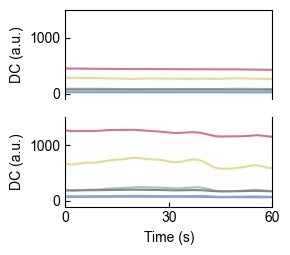

In [126]:
processor.reset()
processor.swt_denoise(wavelet="db2", level=3, zero_levels=(1, 2, 3)).lowpass_filter(cutoff=0.2, order=3)
timestamp, channels_dc = processor.get_data()


fig, (ax1, ax2) = plt.subplots(nrows=2, ncols=1, figsize=(3, 2.65))

for ch in range(channels_dc.shape[1]):
    y = channels_dc[:, ch]
    ax1.plot(timestamp, y, color=colors[ch], linewidth=1.5)
    ax2.plot(timestamp, y, color=colors[ch], linewidth=1.5)

ax1.set_xlim(*ppg_region_1)
ax2.set_xlim(*ppg_region_2)

# ax1.set_ylim(amplitude_limits[0], amplitude_limits[1])
# ax2.set_ylim(amplitude_limits[0], amplitude_limits[1])

for ax in (ax1, ax2):
    ax.tick_params(direction='in')
    ax.tick_params(axis='y')
    ax.set_ylabel('DC (a.u.)')

x1, x2 = ax.get_xlim()
ax2.set_xticks([x1, (x1 + x2) / 2, x2])
ax2.set_xticklabels([0, 30, 60])
ax2.set_xlabel('Time (s)')

ax1.set_ylim(-100, 1500)
ax2.set_ylim(-100, 1500)

ax1.spines['bottom'].set_visible(False)
ax2.spines['top'].set_visible(False)
ax1.set_xticks([])

plt.tight_layout()
plt.savefig('../figures/fig3/mode_a_dc.png', dpi=600, bbox_inches='tight', transparent=True)
plt.show()

# 555S1

In [73]:
processor.load_data('../data/spectraderama_data_2025-03-26_sattac555S1.csv')

# Get raw data for reference
timestamp, channels = processor.get_data()
print(f"Loaded data shape: {channels.shape}")
print(f"First few rows:")
print(pd.DataFrame(channels[:5]))  # Show first few rows like data.head()

Loaded data shape: (343404, 6)
First few rows:
     0    1     2     3    4     5
0  2.0  5.0  13.0  14.0  8.0  14.0
1  2.0  5.0  13.0  14.0  8.0  14.0
2  2.0  5.0  13.0  14.0  8.0  14.0
3  2.0  4.0  12.0  14.0  8.0  13.0
4  2.0  4.0  12.0  14.0  8.0  13.0


In [87]:
# Use processor pipeline to get processed data
processor.swt_denoise(wavelet="db2", level=3, zero_levels=(1, 2, 3))
processor.bandpass_filter(low_freq=0.5, high_freq=2.0, order=3)

# Get processed data
timestamp, channels_swt_f = processor.get_data()
print(f"Processed data shape: {channels_swt_f.shape}")

Processed data shape: (343404, 6)


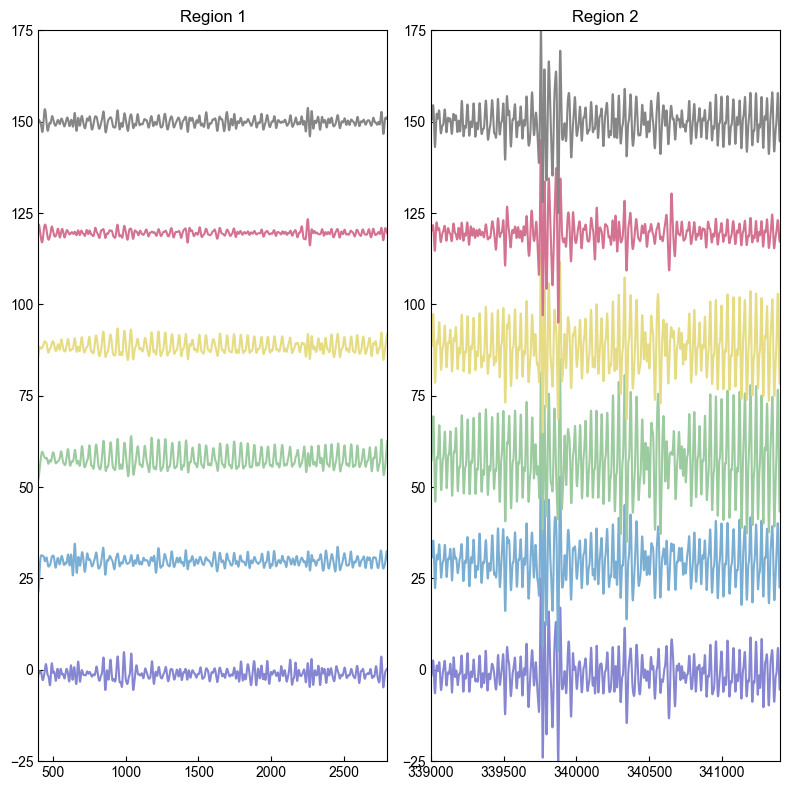

In [88]:
ppg_region_start_1 = 400
ppg_region_end_1 = 2800

ppg_region_start_2 = 339000
ppg_region_end_2 = 341400

ppg_region_1 = (ppg_region_start_1, ppg_region_end_1)
ppg_region_2 = (ppg_region_start_2, ppg_region_end_2)

amplitude_limits = (-25, 25)

processor.normalize(ppg_region_1, ppg_region_2, amplitude_limits=amplitude_limits)
timestamp, channels_swt_f_normalized = processor.get_data()


sample_rate = 30.0
y_offset = 30  # Small offset between channels

fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(8, 8))

for ch in range(channels_swt_f_normalized.shape[1]):
    y = channels_swt_f_normalized[:, ch] + ch * y_offset
    ax1.plot(timestamp, y, color=colors[ch], linewidth=1.5)
    ax2.plot(timestamp, y, color=colors[ch], linewidth=1.5)

ax1.set_xlim(*ppg_region_1)
ax2.set_xlim(*ppg_region_2)

ax1.set_ylim(amplitude_limits[0], amplitude_limits[1] + 5 * y_offset)
ax2.set_ylim(amplitude_limits[0], amplitude_limits[1] + 5 * y_offset)

ax1.set_title("Region 1")
ax2.set_title("Region 2")

for ax in (ax1, ax2):
    ax.tick_params(direction='in')

plt.tight_layout()
plt.show()

# 563S2

In [89]:
processor.load_data('../data/spectraderama_data_2025-03-24_sattac563S2.csv')

# Get raw data for reference
timestamp, channels = processor.get_data()
print(f"Loaded data shape: {channels.shape}")
print(f"First few rows:")
print(pd.DataFrame(channels[:5]))  # Show first few rows like data.head()

Loaded data shape: (31710, 6)
First few rows:
     0    1     2     3     4     5
0  2.0  6.0  18.0  18.0   9.0  13.0
1  2.0  6.0  18.0  18.0   9.0  13.0
2  2.0  6.0  18.0  18.0   9.0  13.0
3  2.0  6.0  17.0  19.0  10.0  13.0
4  3.0  6.0  17.0  19.0  10.0  13.0


In [100]:
# Use processor pipeline to get processed data
processor.swt_denoise(wavelet="db2", level=3, zero_levels=(1, 2, 3))
processor.bandpass_filter(low_freq=0.5, high_freq=2.0, order=3)

# Get processed data
timestamp, channels_swt_f = processor.get_data()
print(f"Processed data shape: {channels_swt_f.shape}")

Processed data shape: (31710, 6)


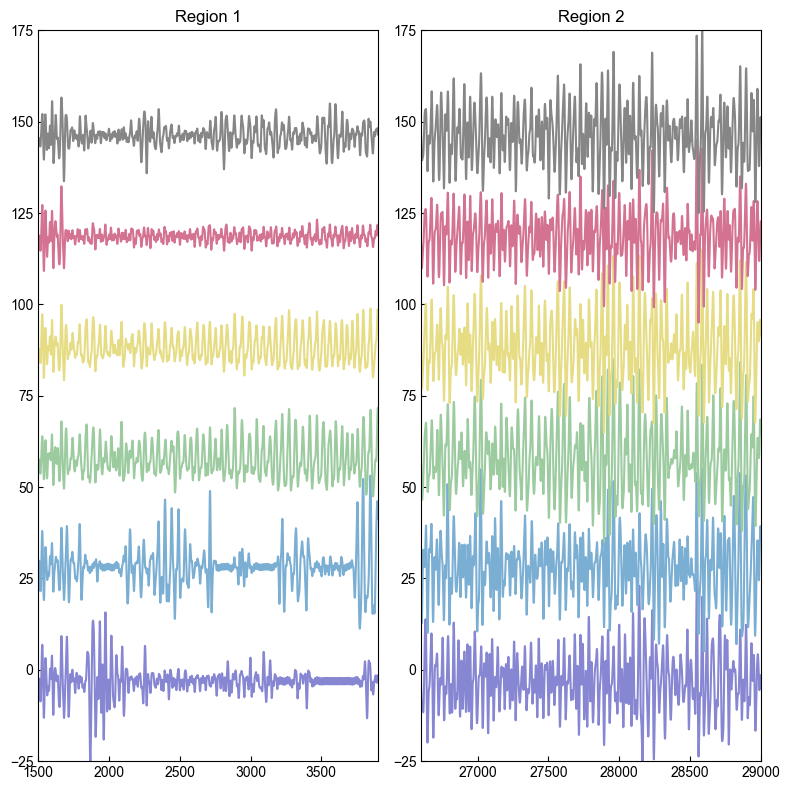

In [102]:
ppg_region_start_1 = 1500
ppg_region_end_1 = 3900

ppg_region_start_2 = 26600
ppg_region_end_2 = 29000

ppg_region_1 = (ppg_region_start_1, ppg_region_end_1)
ppg_region_2 = (ppg_region_start_2, ppg_region_end_2)

amplitude_limits = (-25, 25)

processor.normalize(ppg_region_1, ppg_region_2, amplitude_limits=amplitude_limits)
timestamp, channels_swt_f_normalized = processor.get_data()


sample_rate = 30.0
y_offset = 30  # Small offset between channels

fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(8, 8))

for ch in range(channels_swt_f_normalized.shape[1]):
    y = channels_swt_f_normalized[:, ch] + ch * y_offset
    ax1.plot(timestamp, y, color=colors[ch], linewidth=1.5)
    ax2.plot(timestamp, y, color=colors[ch], linewidth=1.5)

ax1.set_xlim(*ppg_region_1)
ax2.set_xlim(*ppg_region_2)

ax1.set_ylim(amplitude_limits[0], amplitude_limits[1] + 5 * y_offset)
ax2.set_ylim(amplitude_limits[0], amplitude_limits[1] + 5 * y_offset)

ax1.set_title("Region 1")
ax2.set_title("Region 2")

for ax in (ax1, ax2):
    ax.tick_params(direction='in')

plt.tight_layout()
plt.show()